In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import auth
auth.authenticate_user()
import gspread
from oauth2client.client import GoogleCredentials
from google.auth import default

creds, _ = default()
gc = gspread.authorize(creds)
url = 'https://docs.google.com/spreadsheets/d/1ZZ2rwLz9M7-VU5pnLORxCna5Tvp3pMwfCBCcgVKvSEo/edit?resourcekey=&gid=1291793811#gid=1291793811'   # 복사한 스프레드시트 URL 붙이기
worksheet = gc.open_by_url(url).sheet1
rows = worksheet.get_all_values()
df = pd.DataFrame.from_records(rows[1:], columns=rows[0])

display(df)

,타임스탬프,지원자번호,희망업무(복수가능),"자격증 점수(기사:1000,산업기사:900,기능사:800)",토익 점수
0,2026. 11. 26 오후 2:04:51,1,"개발, 기획",1000,800
1,2026. 11. 26 오후 2:05:10,2,"기획, 경영, 영업",900,400
2,2026. 11. 26 오후 2:05:22,3,"경영, 영업",800,900
3,2026. 11. 26 오후 2:05:37,4,"개발, 경영, 영업",900,700
4,2026. 11. 26 오후 2:05:50,5,"개발, 기획, 경영",800,950
5,2026. 11. 26 오후 2:07:59,6,"개발, 영업",900,750
6,2026. 11. 26 오후 2:08:36,7,경영,1000,850


In [12]:
df.rename(columns={'자격증점수기사:1000, 산업기사:900, 기능사:800)':'자격증 점수'},\
          inplace=True)
df.rename(columns={'희망업무(복수가능)':'희망 업무'}, inplace=True)
display(df)

,타임스탬프,지원자번호,희망 업무,"자격증 점수(기사:1000,산업기사:900,기능사:800)",토익 점수
0,2026. 11. 26 오후 2:04:51,1,"개발, 기획",1000,800
1,2026. 11. 26 오후 2:05:10,2,"기획, 경영, 영업",900,400
2,2026. 11. 26 오후 2:05:22,3,"경영, 영업",800,900
3,2026. 11. 26 오후 2:05:37,4,"개발, 경영, 영업",900,700
4,2026. 11. 26 오후 2:05:50,5,"개발, 기획, 경영",800,950
5,2026. 11. 26 오후 2:07:59,6,"개발, 영업",900,750
6,2026. 11. 26 오후 2:08:36,7,경영,1000,850


In [14]:
# 1. 실제 데이터에 있는 정확한 열 이름으로 변경합니다.
df.rename(columns={'자격증 점수(기사:1000,산업기사:900,기능사:800)': '자격증 점수'}, inplace=True)

# 2. '자격증 점수'와 '토익 점수' 열을 정수형(int)으로 변환합니다.
df['자격증 점수'] = df['자격증 점수'].astype(int)
df['토익 점수'] = df['토익 점수'].astype(int)

# 변경된 데이터 타입과 결과 확인
print(df.dtypes)
display(df)

타임스탬프     object
지원자번호     object
희망 업무     object
자격증 점수     int64
토익 점수      int64
dtype: object


,타임스탬프,지원자번호,희망 업무,자격증 점수,토익 점수
0,2026. 11. 26 오후 2:04:51,1,"개발, 기획",1000,800
1,2026. 11. 26 오후 2:05:10,2,"기획, 경영, 영업",900,400
2,2026. 11. 26 오후 2:05:22,3,"경영, 영업",800,900
3,2026. 11. 26 오후 2:05:37,4,"개발, 경영, 영업",900,700
4,2026. 11. 26 오후 2:05:50,5,"개발, 기획, 경영",800,950
5,2026. 11. 26 오후 2:07:59,6,"개발, 영업",900,750
6,2026. 11. 26 오후 2:08:36,7,경영,1000,850


In [15]:
df.drop(columns='타임스탬프', inplace=True)
display(df)

,지원자번호,희망 업무,자격증 점수,토익 점수
0,1,"개발, 기획",1000,800
1,2,"기획, 경영, 영업",900,400
2,3,"경영, 영업",800,900
3,4,"개발, 경영, 영업",900,700
4,5,"개발, 기획, 경영",800,950
5,6,"개발, 영업",900,750
6,7,경영,1000,850


In [18]:
# '토익점수'에 공백을 추가하여 '토익 점수'로 올바르게 호출합니다.
df['합계'] = df['자격증 점수'] + df['토익 점수']
display(df)

,지원자번호,희망 업무,자격증 점수,토익 점수,합계
0,1,"개발, 기획",1000,800,1800
1,2,"기획, 경영, 영업",900,400,1300
2,3,"경영, 영업",800,900,1700
3,4,"개발, 경영, 영업",900,700,1600
4,5,"개발, 기획, 경영",800,950,1750
5,6,"개발, 영업",900,750,1650
6,7,경영,1000,850,1850


In [19]:
df['결과'] = np.where(df['합계']>=1500, '합격', '불합격')
display(df)

,지원자번호,희망 업무,자격증 점수,토익 점수,합계,결과
0,1,"개발, 기획",1000,800,1800,합격
1,2,"기획, 경영, 영업",900,400,1300,불합격
2,3,"경영, 영업",800,900,1700,합격
3,4,"개발, 경영, 영업",900,700,1600,합격
4,5,"개발, 기획, 경영",800,950,1750,합격
5,6,"개발, 영업",900,750,1650,합격
6,7,경영,1000,850,1850,합격


In [20]:
display(df[df['결과']=='합격'])

,지원자번호,희망 업무,자격증 점수,토익 점수,합계,결과
0,1,"개발, 기획",1000,800,1800,합격
2,3,"경영, 영업",800,900,1700,합격
3,4,"개발, 경영, 영업",900,700,1600,합격
4,5,"개발, 기획, 경영",800,950,1750,합격
5,6,"개발, 영업",900,750,1650,합격
6,7,경영,1000,850,1850,합격


In [21]:
df.to_csv('result.csv', index=False)

In [23]:
desired_work = {'개발':0, '기획':0, '경영':0, '영업':0}

In [29]:
# 딕셔너리를 {키: 0}으로 초기화
desired_work = {'개발': 0, '기획': 0, '경영': 0, '영업': 0}

for s in df['희망 업무']:
  for a in s.split(','):
    # strip()을 사용하여 앞뒤 불필요한 공백(' 기획' -> '기획')을 제거합니다.
    clean_key = a.strip()
    if clean_key in desired_work:
      desired_work[clean_key] += 1

print(desired_work)

{'개발': 4, '기획': 3, '경영': 5, '영업': 4}


In [30]:
for key, value in desired_work.items():
  print(key, value)

개발 4
기획 3
경영 5
영업 4


In [33]:
!pip install koreanize-matplotlib

import koreanize_matplotlib

plt.rcParams["font.size"] = 12 # 기본 글꼴 크기
plt.rcParams["axes.titlesize"] = 16 # 제목 크기
plt.rcParams["axes.labelsize"] = 14 # x, y축 라벨 크기
plt.rcParams["xtick.labelsize"] = 11 # x축 눈금 크기
plt.rcParams["ytick.labelsize"] = 11 # y축 눈금 크기
plt.rcParams["legend.fontsize"] = 11 # 범례 크기

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 33 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 2s (5,632 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-nanum.
(Reading database ... 127324 files and

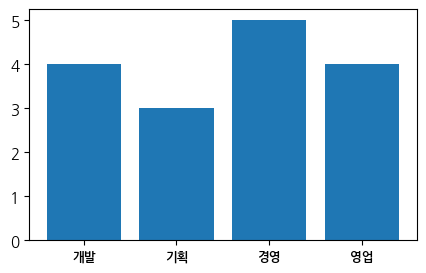

In [34]:
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm -rf ~/.cache/matplotlib
path = '/usr/share/fonts/truetype/nanum/NanumGothicBold.ttf'
import matplotlib.font_manager as fm
font9 = fm.FontProperties(fname=path, size=9)
ind = np.arange(len(desired_work))
plt.figure(figsize=(5,3))
plt.bar(ind, desired_work.values())
plt.xticks(ind, desired_work.keys(), fontproperties=font9)
plt.show()

In [35]:
import numpy as np
import pandas as pd

from google.colab import auth
auth.authenticate_user()
import gspread
from oauth2client.client import GoogleCredentials
from google.auth import default
creds, _ = default()
gc = gspread.authorize(creds)
url = 'https://docs.google.com/spreadsheets/d/1JMzXR44rHXUQILOOsRauNtJ8_1Liz_rBqutU9NNRoTU/edit?resourcekey=&gid=338881708#gid=338881708'   # 복사한 스프레드시트 URL 붙이기
worksheet = gc.open_by_url(url).sheet1
rows = worksheet.get_all_values()
df = pd.DataFrame.from_records(rows[1:], columns=rows[0])

display(df)

,타임스탬프,이름,키,몸무게
0,2026. 11. 26 오후 3:05:22,기기,150,50
1,2026. 11. 26 오후 3:05:33,코코,160,60
2,2026. 11. 26 오후 3:05:44,카카,180,78
3,2026. 11. 26 오후 3:05:58,차차,175,75
4,2026. 11. 26 오후 3:06:12,파파,170,72
5,2026. 11. 26 오후 3:06:28,라라,195,85


In [36]:
df['키'] = df['키'].astype(int)
df['몸무게'] = df['몸무게'].astype(int)

In [37]:
df['체질량지수'] = df['몸무게'] / ((df['키']/100.0)*(df['키']/100.0))

df['판정'] = np.where(df['체질량지수']<18.5, '저체중',
                   np.where(df['체질량지수']<23, '정상',
                      np.where(df['체질량지수']<25, '과체중',
                          np.where(df['체질량지수']<30, '1단계비만',
                              np.where(df['체질량지수']<35, '2단계비만', '고도비만')))))

display(df)

,타임스탬프,이름,키,몸무게,체질량지수,판정
0,2026. 11. 26 오후 3:05:22,기기,150,50,22.222222,정상
1,2026. 11. 26 오후 3:05:33,코코,160,60,23.437500,과체중
2,2026. 11. 26 오후 3:05:44,카카,180,78,24.074074,과체중
3,2026. 11. 26 오후 3:05:58,차차,175,75,24.489796,과체중
4,2026. 11. 26 오후 3:06:12,파파,170,72,24.913495,과체중
5,2026. 11. 26 오후 3:06:28,라라,195,85,22.353715,정상


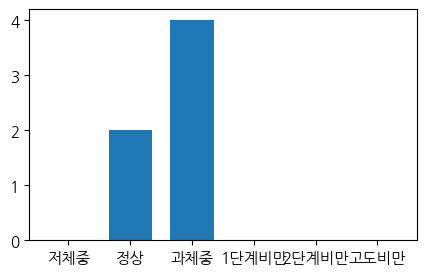

In [38]:
result = {'저체중':0,'정상':0,'과체중':0,'1단계비만':0,'2단계비만':0,'고도비만':0}

for x in df['판정']:
  result[x] = result[x] + 1

plt.figure(figsize=(5,3))
ind = np.arange(len(result))
plt.bar(ind, result.values(), width=0.7)
plt.xticks(ind, result.keys())
plt.show()